**Libaries**

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

**config**

In [95]:
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 5)
RANDOM_STATE = 42

**load the data**

In [96]:
df = pd.read_csv("Mall_Customers.csv")
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**quick check and cleanup**

In [97]:
# Quick checks and cleanup
df.info()
df = df.rename(columns={"Genre": "Gender"})
df.columns = [c.strip() for c in df.columns]
print("\nMissing values per column:\n", df.isna().sum())
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values per column:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


**Exploratory data analysis**

**Distributions: Income, Spending, Age**

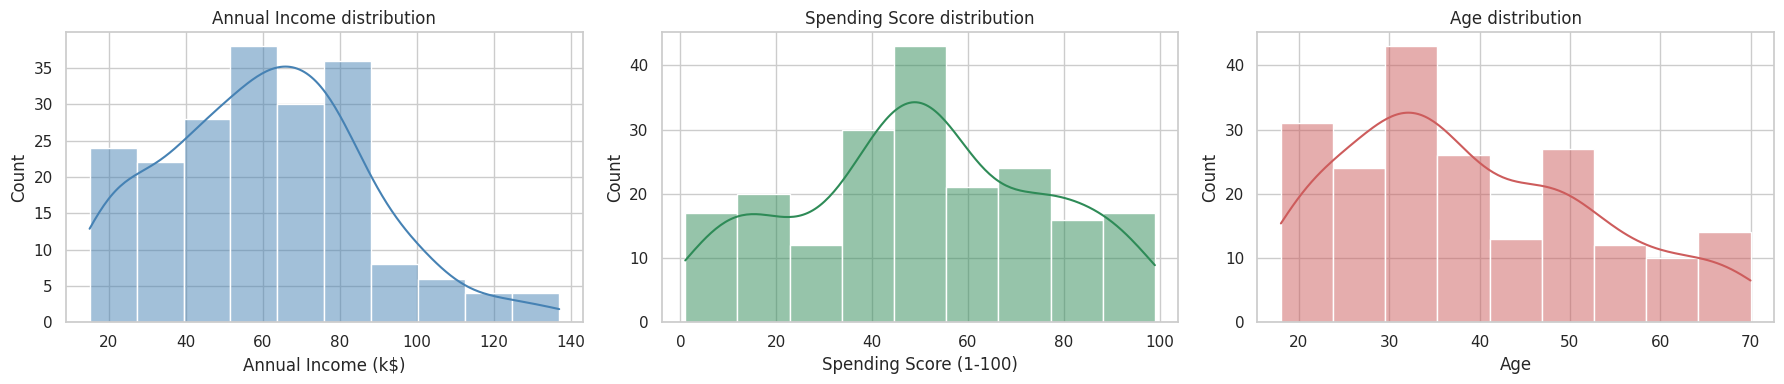

In [98]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))
sns.histplot(df['Annual Income (k$)'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Annual Income distribution")
sns.histplot(df['Spending Score (1-100)'], kde=True, ax=axes[1], color='seagreen')
axes[1].set_title("Spending Score distribution")
sns.histplot(df['Age'], kde=True, ax=axes[2], color='indianred')
axes[2].set_title("Age distribution")
plt.tight_layout()
plt.show()

**Relationship: Income vs Spending**

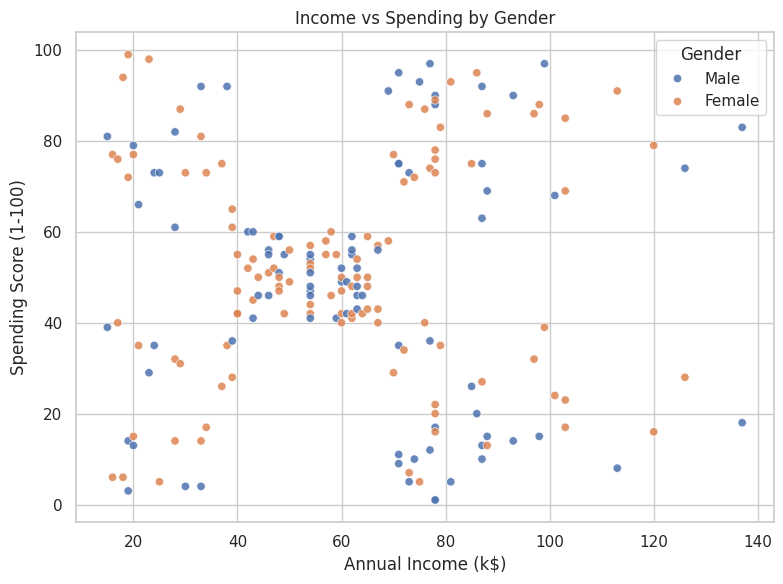

In [99]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', hue='Gender', data=df, alpha=0.85)
plt.title("Income vs Spending by Gender")
plt.tight_layout()
plt.show()

**Features and scaling**

In [100]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled sample (first 5 rows):\n", X_scaled[:5])

Scaled sample (first 5 rows):
 [[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


**Determine optimal k**

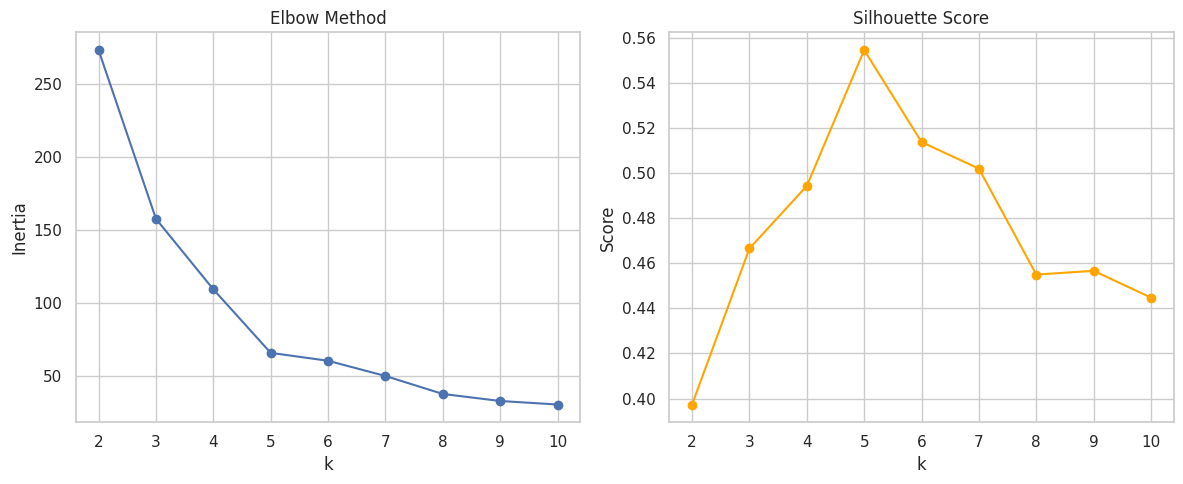

Best k (by silhouette): 5


In [101]:
ks = range(2, 11)
inertias, silhouettes = [], []

for k in ks:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init='auto')
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(list(ks), inertias, marker='o')
plt.title("Elbow Method")
plt.xlabel("k"); plt.ylabel("Inertia")

plt.subplot(1,2,2)
plt.plot(list(ks), silhouettes, marker='o', color='orange')
plt.title("Silhouette Score")
plt.xlabel("k"); plt.ylabel("Score")
plt.tight_layout()
plt.show()

best_k = ks[int(np.argmax(silhouettes))]
print("Best k (by silhouette):", best_k)

**K-Means clustering, visualization, and profiling**

In [102]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init='auto')
df['Cluster_KMeans'] = kmeans.fit_predict(X_scaled)

centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers, columns=features)
centers_df['Cluster'] = range(best_k)

cluster_sizes = df['Cluster_KMeans'].value_counts().sort_index()
centers_df['Count'] = centers_df['Cluster'].map(cluster_sizes)

centers_df

,Annual Income (k$),Spending Score (1-100),Cluster,Count
0,55.296296,49.518519,0,81
1,86.538462,82.128205,1,39
2,25.727273,79.363636,2,22
3,88.200000,17.114286,3,35
4,26.304348,20.913043,4,23


**Visualization with centers**

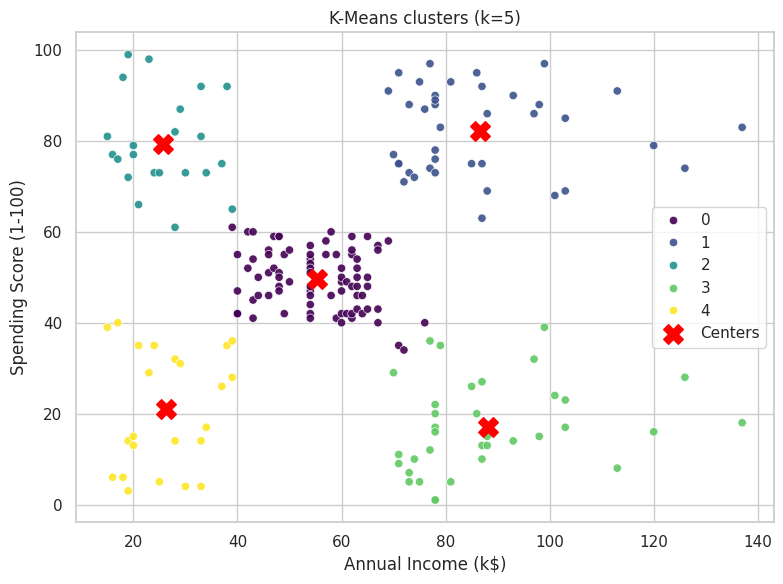

In [103]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster_KMeans', data=df, palette='viridis', alpha=0.9)
plt.scatter(centers[:,0], centers[:,1], c='red', s=200, marker='X', label='Centers')
plt.title(f"K-Means clusters (k={best_k})")
plt.legend()
plt.tight_layout()
plt.savefig("kmeans_clusters.png", dpi=200)
plt.show()

**profiling**

In [104]:
profile = df.groupby('Cluster_KMeans').agg({
    'Annual Income (k$)': ['mean', 'median', 'min', 'max'],
    'Spending Score (1-100)': ['mean', 'median', 'min', 'max'],
    'Age': ['mean', 'median']
})
profile.columns = ['_'.join(col) for col in profile.columns]
profile

,Annual Income (k$)_mean,Annual Income (k$)_median,Annual Income (k$)_min,Annual Income (k$)_max,Spending Score (1-100)_mean,Spending Score (1-100)_median,Spending Score (1-100)_min,Spending Score (1-100)_max,Age_mean,Age_median
Cluster_KMeans,,,,,,,,,,
0,55.296296,54.0,39,76,49.518519,50.0,34,61,42.716049,46.0
1,86.538462,79.0,69,137,82.128205,83.0,63,97,32.692308,32.0
2,25.727273,24.5,15,39,79.363636,77.0,61,99,25.272727,23.5
3,88.200000,85.0,70,137,17.114286,16.0,1,39,41.114286,42.0
4,26.304348,25.0,15,39,20.913043,17.0,3,40,45.217391,46.0


**Semantic segment labels from centers**

In [105]:
income_med = df['Annual Income (k$)'].median()
spend_med = df['Spending Score (1-100)'].median()

def semantic_label(row):
    income, spend = row['Annual Income (k$)'], row['Spending Score (1-100)']
    if income >= income_med and spend >= spend_med:
        return "High income, high spending (Premium)"
    elif income >= income_med and spend < spend_med:
        return "High income, low spending (Cautious)"
    elif income < income_med and spend >= spend_med:
        return "Low income, high spending (Value seekers)"
    else:
        return "Low income, low spending (Budget)"

centers_df['SegmentLabel'] = centers_df.apply(semantic_label, axis=1)
label_map = centers_df.set_index('Cluster')['SegmentLabel'].to_dict()
df['Segment'] = df['Cluster_KMeans'].map(label_map)

**Segment summary for stakeholders**

In [106]:
summary_stats = df.groupby(['Cluster_KMeans', 'Segment']).agg(
    AvgIncome=('Annual Income (k$)', 'mean'),
    AvgSpending=('Spending Score (1-100)', 'mean'),
    AvgAge=('Age', 'mean'),
    Count=('CustomerID', 'count')
).reset_index().sort_values('Cluster_KMeans')

summary_stats

,Cluster_KMeans,Segment,AvgIncome,AvgSpending,AvgAge,Count
0,0,"Low income, low spending (Budget)",55.296296,49.518519,42.716049,81
1,1,"High income, high spending (Premium)",86.538462,82.128205,32.692308,39
2,2,"Low income, high spending (Value seekers)",25.727273,79.363636,25.272727,22
3,3,"High income, low spending (Cautious)",88.200000,17.114286,41.114286,35
4,4,"Low income, low spending (Budget)",26.304348,20.913043,45.217391,23


***Alternative clustering and PCA visualization***

**Agglomerative clustering (Ward linkage)**

Agglomerative silhouette: 0.5538089226688662


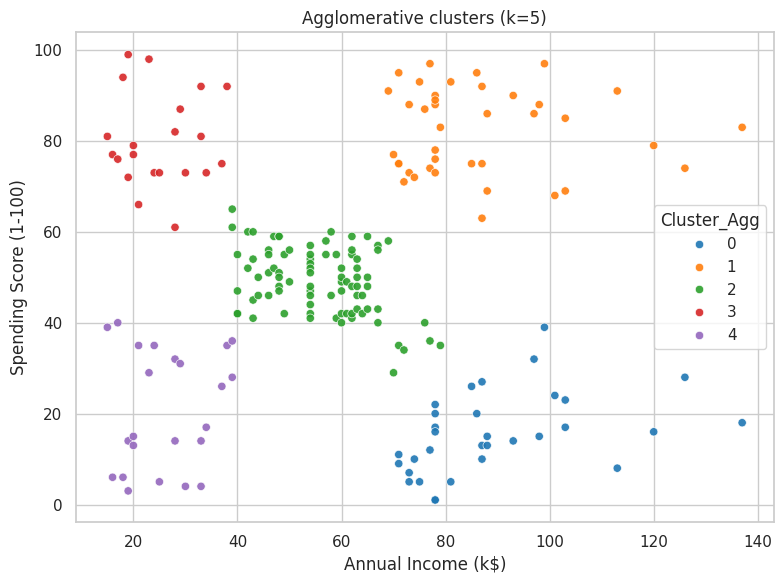

In [107]:
agg = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
df['Cluster_Agg'] = agg.fit_predict(X_scaled)
sil_agg = silhouette_score(X_scaled, df['Cluster_Agg'])
print("Agglomerative silhouette:", sil_agg)

plt.figure(figsize=(8,6))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster_Agg', data=df, palette='tab10', alpha=0.9)
plt.title(f"Agglomerative clusters (k={best_k})")
plt.tight_layout()
plt.savefig("agg_clusters.png", dpi=200)
plt.show()

**DBSCAN: MinMax scaling + k-distance plot**

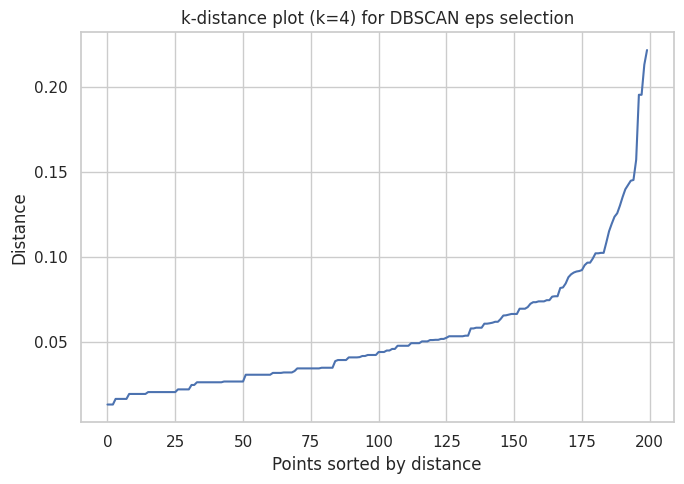

In [108]:
mm = MinMaxScaler()
X_mm = mm.fit_transform(X)

nbrs = NearestNeighbors(n_neighbors=4).fit(X_mm)
distances, _ = nbrs.kneighbors(X_mm)
kdist = np.sort(distances[:, -1])
plt.figure(figsize=(7,5))
plt.plot(kdist)
plt.title("k-distance plot (k=4) for DBSCAN eps selection")
plt.xlabel("Points sorted by distance"); plt.ylabel("Distance")
plt.tight_layout()
plt.show()

**Choose eps based on elbow; start with 0.1 and adjust if needed**

DBSCAN labels (including noise=-1): [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
DBSCAN silhouette (excluding noise): 0.5630963660280011


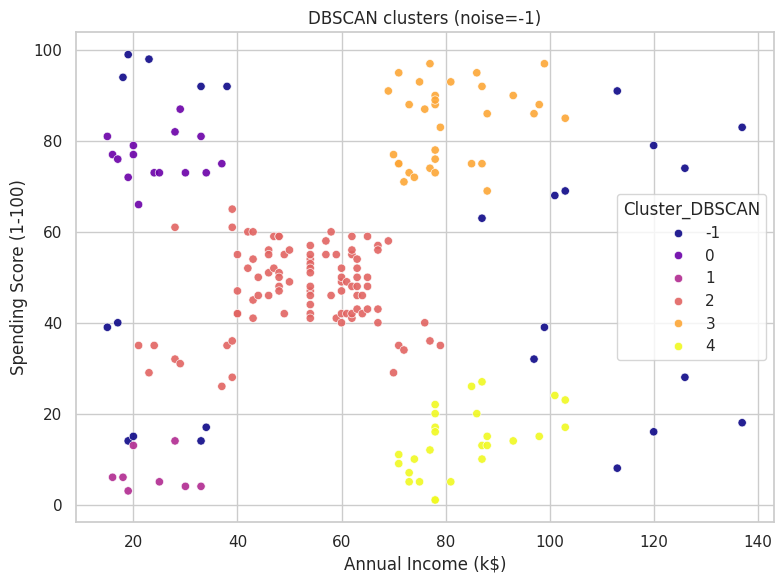

In [109]:
dbscan = DBSCAN(eps=0.1, min_samples=8)
db_labels = dbscan.fit_predict(X_mm)
df['Cluster_DBSCAN'] = db_labels
unique_db = sorted(set(db_labels))
print("DBSCAN labels (including noise=-1):", unique_db)

valid = db_labels != -1
if valid.sum() > 0 and len(set(db_labels[valid])) >= 2:
    sil_db = silhouette_score(X_mm[valid], db_labels[valid])
    print("DBSCAN silhouette (excluding noise):", sil_db)
else:
    sil_db = np.nan

plt.figure(figsize=(8,6))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster_DBSCAN', data=df, palette='plasma', alpha=0.9)
plt.title("DBSCAN clusters (noise=-1)")
plt.tight_layout()
plt.savefig("dbscan_clusters.png", dpi=200)
plt.show()

**Method comparison**

In [110]:
kmeans_sil = silhouette_score(X_scaled, df['Cluster_KMeans'])
comparison = pd.DataFrame({
    "Method": ["KMeans", "Agglomerative", "DBSCAN (excl. noise)"],
    "Silhouette": [kmeans_sil, sil_agg, sil_db]
})
comparison

,Method,Silhouette
0,KMeans,0.554657
1,Agglomerative,0.553809
2,DBSCAN (excl. noise),0.563096


**PCA projection of current features**

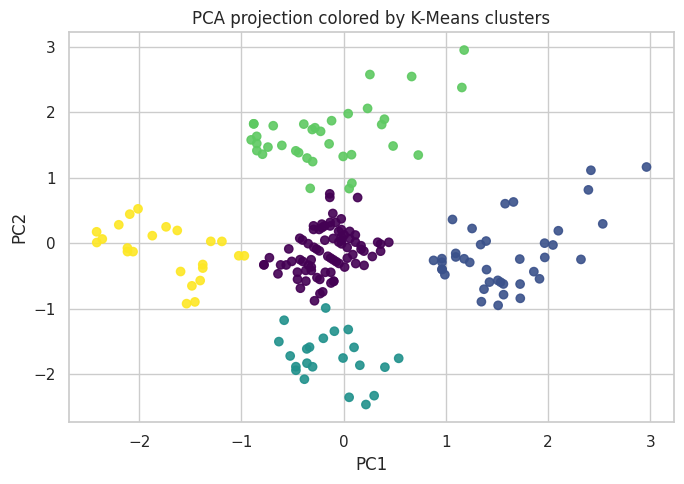

In [111]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(7,5))
plt.scatter(X_pca[:,0], X_pca[:,1], c=df['Cluster_KMeans'], cmap='viridis', alpha=0.9)
plt.title("PCA projection colored by K-Means clusters")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout()
plt.savefig("pca_kmeans.png", dpi=200)
plt.show()

**Export CSVs**

In [112]:
df.to_csv("mall_customers_clustered.csv", index=False)
centers_df.to_csv("kmeans_centers.csv", index=False)
profile.to_csv("cluster_profile.csv")
summary_stats.to_csv("segment_summary.csv", index=False)
comparison.to_csv("method_comparison.csv", index=False)

print("Saved: mall_customers_clustered.csv, kmeans_centers.csv, cluster_profile.csv, segment_summary.csv, method_comparison.csv")
print("Saved figures: kmeans_clusters.png, agg_clusters.png, dbscan_clusters.png, pca_kmeans.png")

Saved: mall_customers_clustered.csv, kmeans_centers.csv, cluster_profile.csv, segment_summary.csv, method_comparison.csv
Saved figures: kmeans_clusters.png, agg_clusters.png, dbscan_clusters.png, pca_kmeans.png
